# 分步骤复现 Figure 3A 与 Table III

这份 Notebook 把 `run_reproduction.py` 的工作拆开。**按顺序运行单元**，每一步都能看到输出；计算只调用作者的 `get_8_SAT_params`，没有调用 `run_reproduction.main()`。

任务顺序：① 固定参数 → ② 读经典拟合 → ③ 找交叉点 → ④ 拆解成功概率、幅度放大与 $G$ → ⑤ 算表面码码距 → ⑥ 核对工厂、译码器、量子比特和时间 → ⑦ 对照 Table III → ⑧ 重画 Figure 3A。

> 这是一份**资源估计**复现：沿用论文的 QAOA 成功概率模型，估算实现成本。没有对具体 SAT 实例运行 QAOA 电路，因此 Eq. (3) 的状态制备和 Eq. (19)–(20) 的子句相位门没有逐门仿真。

## 0. 对照 `run_reproduction.py` 看每一步

- `CASES`、`classical_fit()` → 下面的**第 1、2 步**：输入与经典拟合。
- `calculate()`、`first_crossover()` → **第 3 步**：调用作者模型并搜索 $T_q\le T_c$。
- `main()` 里计算 `surface_failure_bound` → **第 4、5 步**：把 $G$ 和码距展开。
- `save_csv()`、`save_comparison()` → **第 7 步**：形成 Table III 对照。
- `plot_figure_3a()`、`plot_g_and_surface_code()` → **第 8 步**：分别画两张图。

**论文位置**：经典拟合 Eq. (1)；QAOA+AA Eq. (6)–(7)；时间 Eq. (8)–(11)；并行任务 Eq. (12)；旋转分解 Eq. (14)–(18)；表面码 Eq. (21)–(24)；交叉结果 Fig. 3A 与 Table III。

## 1. 固定输入参数

**论文位置**：Fig. 1E 给出不同 QAOA 深度对应的渐进加速；Fig. 3A 和 Table III 给出 quadratic / cubic / quartic 三种情形。物理错误率、保真度和工厂假设见 Fig. 3 图注及 Methods。

下面 `PAPER` 中的数字**仅用于结果对照**。计算交叉点时只使用 `speedup` 与搜索范围，不把论文的 $n$ 输入为答案。

In [1]:
from pathlib import Path
import csv
import math
import os
import sys

def find_simulation_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / "simulation"):
            if (candidate / "src" / "author_utils_notebook.py").is_file():
                return candidate
    raise FileNotFoundError("请从 code 或 simulation 文件夹中打开本 Notebook。")

ROOT = find_simulation_root()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mpl_cache"))
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
import author_utils_notebook as author  # 运行模型；参考副本在 ../reference/

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

# 每组只固定渐进加速目标；论文 n 用于事后核对。
CASES = [
    ("quadratic", 2, range(220, 260)),
    ("cubic", 3, range(175, 210)),
    ("quartic", 4, range(165, 195)),
]
PAPER = {
    "quadratic": dict(n=242, p=71, d=35, G_1e12=419.0, depth_1e8=6750.25,
                      qubits_m=152.43, jobs=840, ancilla=43680, decoder=52320,
                      cores=71, NT=27, eps_rot=1.76e-9, eps_T=1e-17, hours=3*365*24),
    "cubic": dict(n=191, p=253, d=29, G_1e12=0.96, depth_1e8=20.76,
                  qubits_m=84.43, jobs=592, ancilla=30784, decoder=36900,
                  cores=50, NT=24, eps_rot=6.65e-8, eps_T=1.44e-14, hours=64.57),
    "quartic": dict(n=179, p=623, d=28, G_1e12=0.21, depth_1e8=5.0,
                    qubits_m=73.91, jobs=540, ancilla=28080, decoder=33660,
                    cores=46, NT=23, eps_rot=1.41e-7, eps_T=6.48e-14, hours=14.99),
}

p_ph = 1e-3       # 物理错误率
p_th = 1e-2       # 表面码阈值
target_F = 0.99   # 目标电路保真度；允许的失败概率是 1 - target_F = 0.01
code_cycle = 1e-6 # 表面码一个纠错周期的秒数
tau = 1           # 相邻子句批次的派发间隔（逻辑周期数）
b, c = 0.57, 9    # 作者源码使用的旋转分解系数
factory_qubits = 46800 * (157 / 30) / 4  # 一个资源态工厂的物理量子比特占用

print("搜索组别：", [(name, speedup) for name, speedup, _ in CASES])
print("表面码输入：p_ph =", p_ph, ", p_th =", p_th, ", 目标保真度 =", target_F)

搜索组别： [('quadratic', 2), ('cubic', 3), ('quartic', 4)]
表面码输入：p_ph = 0.001 , p_th = 0.01 , 目标保真度 = 0.99


## 2. 读取经典求解器拟合参数

**论文位置**：Eq. (1) 给出 Sparrow 的串行时间 $T_c(n)=2^{0.176n+19.369}$ 纳秒。并行修正来自经典运行时间分布；作者 Fig. 3B/3D 的 notebook 选择 `optimized_parameters.txt` 的第三组 Rand-9。

`lambda` 是移位指数分布的速率，`shift` 是最短时间的平移量。这里的两个量不是 QAOA 的角度参数。

In [2]:
line = (ROOT / "data" / "optimized_parameters.txt").read_text(encoding="utf-8").splitlines()[2]
shift = float(line.split(",")[0].split(":")[-1])
lambda_rate = float(line.split(",")[1].split(":")[-1])

# n_cores 个独立移位指数运行时间中的最小值，期望为 shift + 1/(n_cores*lambda)。
# 这是 author_utils_notebook.py 中替代原版 SciPy 积分的等价解析式。
def parallel_factor(n_cores):
    return (shift + 1/(n_cores*lambda_rate)) / (shift + 1/lambda_rate)

print("Rand-9 原始行：", line)
print(f"shift = {shift:.6f} ns, lambda = {lambda_rate:.9f} /ns")
print(f"示例：50 个经典核心的并行时间比例 = {parallel_factor(50):.5f}")

Rand-9 原始行： Rand-9 - Optimized shift: 6.774964035648691, Calculated lambda: 0.0009790243677117985
shift = 6.774964 ns, lambda = 0.000979024 /ns
示例：50 个经典核心的并行时间比例 = 0.02646


## 3. 调用作者函数，搜索 Figure 3A 的交叉点

**论文位置**：Section II.E、Fig. 3A、Table III。交叉条件是 $T_q(n,p)\le T_c(n)$。作者函数同时计算两种时间及资源。以下单元先显示单次调用返回了什么，再逐个试整数 $n$ 找第一个交叉点。

`get_8_SAT_params` 返回的是长元组；下面把常用位置明确命名，便于知道 Table III 每一列从哪里来。

In [3]:
def evaluate(n, speedup):
    # 参数顺序与作者 get_8_SAT_params 的定义完全一致。
    x = author.get_8_SAT_params(
        n, p_ph, code_cycle, speedup, 2, tau, b, c,
        factory_qubits, lambda_rate, shift, False,
    )
    return {
        "n": n, "speedup": speedup, "p": int(x[1]),
        "G": float(x[2]), "depth": int(x[3]), "d": int(x[4]),
        "NT": int(x[5]), "eps_T": float(x[6]),
        "log_Tc": float(x[8]), "log_Tq": float(x[9]),
        "jobs": int(x[10]), "qubits": int(x[11]), "cores": int(x[12]),
        "ancilla": int(x[14]), "decoder": int(x[15]),
        "eps_rot": float(x[16]),
    }

example = evaluate(179, 4)
print("n=179、四次加速的单次调用：")
print({key: example[key] for key in ("p", "G", "d", "jobs", "qubits")})

n=179、四次加速的单次调用：
{'p': 623, 'G': 210649368048.0, 'd': 27, 'jobs': 540, 'qubits': 74265822}


In [4]:
rows = []
for name, speedup, search_range in CASES:
    # 从小到大搜索；论文 n 不参与这段循环。
    for n in search_range:
        row = evaluate(n, speedup)
        if row["log_Tc"] >= row["log_Tq"]:  # 对数保序，等价于 Tc >= Tq。
            row["case"] = name
            row["Tq_hours"] = math.exp(row["log_Tq"]) / 3600
            row["Tc_hours"] = math.exp(row["log_Tc"]) / 3600
            rows.append(row)
            break
    else:
        raise RuntimeError(f"{name} 在给定 n 范围内没有交叉点")

for row in rows:
    print(f"{row['case']:9s}: n={row['n']} (论文 {PAPER[row['case']]['n']}), "
          f"p={row['p']}, Tq={row['Tq_hours']:.3f} h, Tc={row['Tc_hours']:.3f} h")

quadratic: n=242 (论文 242), p=71, Tq=25500.940 h, Tc=25661.404 h
cubic    : n=191 (论文 191), p=253, Tq=64.550 h, Tc=65.512 h
quartic  : n=179 (论文 179), p=623, Tq=14.990 h, Tc=16.144 h


## 4. 拆开看成功概率、幅度放大和 $G$

**论文位置**：Eq. (5) 后给出经验成功概率 $P_{\rm QAOA}=2^{-0.69p^{-0.32}n}$；Eq. (6)–(7) 给出幅度放大的电路和大约 $R=\pi/(4\sqrt P)$ 次重复。作者代码把 $R$ 转成整数，并据此估算旋转门总数。

旋转分解见 Eq. (14)、(17)–(18)。需要区分：`N_rot` 是旋转门的**个数**；`G` 是把旋转与其他非 Clifford 开销算进去之后的**总门数上界**，对应 Table III 的 non-Clifford gates 列。论文不同段落都写 $G$，上下文所指未必完全相同。

In [5]:
for row in rows:
    n, p, NT = row["n"], row["p"], row["NT"]
    P_success = 2 ** (-0.69 * p ** (-0.32) * n)
    R = int(math.pi / (4 * math.sqrt(P_success)))
    N_rot = 2 * p * n * (176 + 1) * R
    G_from_parts = N_rot * (7 + NT)
    assert math.isclose(G_from_parts, row["G"])
    row.update(P_success=P_success, AA_repetitions=R, N_rot=N_rot)
    print(f"{row['case']:9s}: P={P_success:.3e}, AA次数={R:,}, "
          f"旋转门={N_rot:.3e}, N_T={NT}, G={G_from_parts:.3e}")

quadratic: P=1.416e-13, AA次数=2,087,482, 旋转门=1.270e+13, N_T=26, G=4.190e+14
cubic    : P=1.766e-07, AA次数=1,868, 旋转门=3.195e+10, N_T=23, G=9.586e+11
quartic  : P=1.806e-05, AA次数=184, 旋转门=7.264e+09, N_T=22, G=2.106e+11


## 5. 从 $G$ 算表面码码距 $d$

**论文位置**：Methods Eq. (21)–(23)；Table III 的 code distance 列。若单个非 Clifford 操作的错误量级为 $(p_{ph}/p_{th})^{d/2}$，则联合上界约为

$$I\lesssim G(p_{ph}/p_{th})^{d/2}.$$

作者代码把 `acc=0.99` 作为**目标保真度**，因此容许失败概率是 $1-0.99=0.01$。Eq. (23) 附近的 $I_{tar}$ 文字记号容易混淆；这里按源码计算，不将 0.99 当作容许失败概率。

In [6]:
q = p_ph / p_th
for row in rows:
    G = row["G"]
    # 先算尚未取整的临界值，再展示作者实际使用的 int(...) + 1。
    d_continuous = 2 * (math.log(1-target_F) - math.log(G)) / math.log(q)
    d_from_formula = int(d_continuous) + 1
    bound = G * q ** (d_from_formula/2)
    assert d_from_formula == row["d"] and bound <= 1-target_F
    row["failure_bound"] = bound
    print(f"{row['case']:9s}: 临界值={d_continuous:.3f}, 源码 d={row['d']}, "
          f"失败上界={bound:.5f}, 论文 d={PAPER[row['case']]['d']}")

print("注意：三个源码 d 都比 Table III 小 1；这里不调整源码输出。")

quadratic: 临界值=33.244, 源码 d=34, 失败上界=0.00419, 论文 d=35
cubic    : 临界值=27.963, 源码 d=28, 失败上界=0.00959, 论文 d=29
quartic  : 临界值=26.647, 源码 d=27, 失败上界=0.00666, 论文 d=28
注意：三个源码 d 都比 Table III 小 1；这里不调整源码输出。


## 6. 核对并行任务、工厂、译码器、物理量子比特和时间

**论文位置**：Eq. (9) 是 phaser 时间，Eq. (12) 是并行 TACU 任务数，Eq. (24) 是译码器数；Fig. 3A 与 Table III 给出最终资源。下面把作者函数内部几个简单的资源式重新算一次，检查它的返回值。

物理量子比特由**工厂占用**与**数据/辅助逻辑量子比特的表面码占用**两部分相加。总逻辑深度综合 phaser、mixer 和两个 oracle 的成本；时间公式还乘表面码周期、码距以及源码中的额外 4 倍幅度放大常数。

In [7]:
for row in rows:
    n, d, NT = row["n"], row["d"], row["NT"]
    parallel_clauses = math.ceil(n/12)            # 每批可并行处理的子句数
    task_cycles = (4*math.log2(8) + NT + 2) / tau # 一个任务占用的逻辑周期数
    jobs = math.ceil(task_cycles * parallel_clauses)
    ancilla = int(13*math.ceil(8/2)*task_cycles*parallel_clauses)
    decoder = 10*jobs + n + ancilla              # 对应 Eq. (24)
    factory_part = factory_qubits * jobs
    data_part = 2*d*d*(n+ancilla)
    physical = int(factory_part + data_part)
    Tq_hours_check = 4*row["depth"]*code_cycle*tau*d/3600
    Tc_hours_check = (2**(19.369+0.176*n))*1e-9*parallel_factor(row["cores"])/3600

    assert (jobs, ancilla, decoder, physical) == (row["jobs"], row["ancilla"], row["decoder"], row["qubits"])
    assert math.isclose(Tq_hours_check, row["Tq_hours"])
    assert math.isclose(Tc_hours_check, row["Tc_hours"])
    print(f"{row['case']:9s}: 任务/工厂={jobs}, 辅助逻辑比特={ancilla}, "
          f"译码器={decoder}, 物理比特={physical/1e6:.3f} 百万")
    print(f"             工厂占 {factory_part/1e6:.3f} 百万，数据与辅助占 {data_part/1e6:.3f} 百万；"
          f"逻辑深度={row['depth']/1e8:.3f}×10^8，Tq={Tq_hours_check:.3f} h")

quadratic: 任务/工厂=840, 辅助逻辑比特=43680, 译码器=52322, 物理比特=152.981 百万
             工厂占 51.433 百万，数据与辅助占 101.548 百万；逻辑深度=6750.249×10^8，Tq=25500.940 h
cubic    : 任务/工厂=592, 辅助逻辑比特=30784, 译码器=36895, 物理比特=84.817 百万
             工厂占 36.248 百万，数据与辅助占 48.569 百万；逻辑深度=20.748×10^8，Tq=64.550 h
quartic  : 任务/工厂=540, 辅助逻辑比特=28080, 译码器=33659, 物理比特=74.266 百万
             工厂占 33.064 百万，数据与辅助占 41.202 百万；逻辑深度=4.997×10^8，Tq=14.990 h


## 7. 与论文 Table III 逐列对照

**论文位置**：Extended Data **Table III**。下方每格按“仿真 / 论文”显示。论文只在这里作为参照值；所有“作者源码”数值都来自前面的计算。输出也保存为 `results/notebook_table_III.csv`。

最值得检查的列：$n,p,G,d$、逻辑深度、物理量子比特、任务/工厂数、辅助逻辑比特、译码器数和交叉时间。对于源码与论文的差异，请保留原值，不要为了对齐而更改公式。

In [8]:
compare = [
    ("n", lambda r:r["n"], "n"), ("p", lambda r:r["p"], "p"),
    ("d", lambda r:r["d"], "d"),
    ("G / 10¹²", lambda r:r["G"]/1e12, "G_1e12"),
    ("逻辑深度 / 10⁸", lambda r:r["depth"]/1e8, "depth_1e8"),
    ("物理比特 / 百万", lambda r:r["qubits"]/1e6, "qubits_m"),
    ("任务/工厂数", lambda r:r["jobs"], "jobs"),
    ("辅助逻辑比特", lambda r:r["ancilla"], "ancilla"),
    ("译码器数", lambda r:r["decoder"], "decoder"),
    ("经典核心数", lambda r:r["cores"], "cores"),
    ("每次旋转 T 门数", lambda r:r["NT"], "NT"),
    ("旋转分解误差", lambda r:r["eps_rot"], "eps_rot"),
    ("T 态错误率", lambda r:r["eps_T"], "eps_T"),
    ("量子时间 / 小时", lambda r:r["Tq_hours"], "hours"),
]
def fmt(value):
    return f"{value:.4g}" if isinstance(value, float) else str(value)

lines = ["| 指标 | quadratic：仿真 / 论文 | cubic：仿真 / 论文 | quartic：仿真 / 论文 |",
         "|---|---:|---:|---:|"]
for label, source, paper_key in compare:
    values = [fmt(source(row)) + " / " + fmt(PAPER[row["case"]][paper_key]) for row in rows]
    lines.append("| " + label + " | " + " | ".join(values) + " |")
display(Markdown("\n".join(lines)))

with (RESULTS/"notebook_table_III.csv").open("w", newline="", encoding="utf-8-sig") as f:
    fields = ["case", "n", "p", "G", "d", "failure_bound", "depth", "jobs", "ancilla",
              "decoder", "cores", "NT", "eps_rot", "eps_T", "qubits", "Tq_hours", "Tc_hours"]
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    for row in rows:
        writer.writerow({field: row[field] for field in fields})
print("已保存 results/notebook_table_III.csv")

| 指标 | quadratic：仿真 / 论文 | cubic：仿真 / 论文 | quartic：仿真 / 论文 |
|---|---:|---:|---:|
| n | 242 / 242 | 191 / 191 | 179 / 179 |
| p | 71 / 71 | 253 / 253 | 623 / 623 |
| d | 34 / 35 | 28 / 29 | 27 / 28 |
| G / 10¹² | 419 / 419 | 0.9586 / 0.96 | 0.2106 / 0.21 |
| 逻辑深度 / 10⁸ | 6750 / 6750 | 20.75 / 20.76 | 4.997 / 5 |
| 物理比特 / 百万 | 153 / 152.4 | 84.82 / 84.43 | 74.27 / 73.91 |
| 任务/工厂数 | 840 / 840 | 592 / 592 | 540 / 540 |
| 辅助逻辑比特 | 43680 / 43680 | 30784 / 30784 | 28080 / 28080 |
| 译码器数 | 52322 / 52320 | 36895 / 36900 | 33659 / 33660 |
| 经典核心数 | 71 / 71 | 50 / 50 | 46 / 46 |
| 每次旋转 T 门数 | 26 / 27 | 23 / 24 | 22 / 23 |
| 旋转分解误差 | 1.756e-09 / 1.76e-09 | 6.654e-08 / 6.65e-08 | 1.414e-07 / 1.41e-07 |
| T 态错误率 | 1e-17 / 1e-17 | 1.436e-14 / 1.44e-14 | 6.485e-14 / 6.48e-14 |
| 量子时间 / 小时 | 2.55e+04 / 26280 | 64.55 / 64.57 | 14.99 / 14.99 |

已保存 results/notebook_table_III.csv


## 8A. 重画 Figure 3A 的关键数值

**论文位置**：主文 **Figure 3A**，它总结二次、三次、四次加速交叉点的规模、物理比特和时间。这里额外把对应的 QAOA 深度 $p$ 放进同一张摘要图，方便检查。蓝色是本 Notebook 算出的值，橙色是论文值；图形布局是教学版，不复制原图。

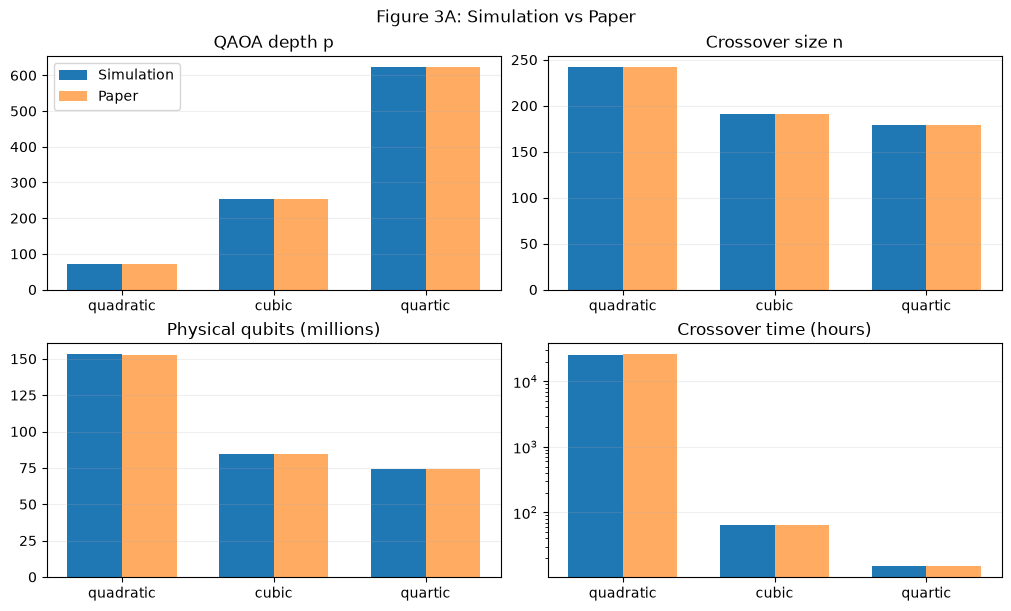

In [9]:
names = [row["case"] for row in rows]
xx = range(3)
fig, axs = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
panels = [
    ("QAOA depth p", lambda r:r["p"], "p"),
    ("Crossover size n", lambda r:r["n"], "n"),
    ("Physical qubits (millions)", lambda r:r["qubits"]/1e6, "qubits_m"),
    ("Crossover time (hours)", lambda r:r["Tq_hours"], "hours"),
]
for ax, (title, source, paper_key) in zip(axs.flat, panels):
    ax.bar([i-.18 for i in xx], [source(row) for row in rows], .36, label="Simulation")
    ax.bar([i+.18 for i in xx], [PAPER[name][paper_key] for name in names], .36,
           label="Paper", alpha=.65)
    ax.set_xticks(list(xx), names)
    ax.set_title(title)
    ax.grid(axis="y", alpha=.2)
    if paper_key == "hours": ax.set_yscale("log")  # 数年与数小时同图显示。
axs[0,0].legend()
fig.suptitle("Figure 3A: Simulation vs Paper")
fig.savefig(RESULTS/"notebook_figure_3A.png", dpi=180)
plt.show()

## 8B. 单独看你重点关心的 $G$ 与表面码

**论文位置**：Table III 的 non-Clifford gates 和 code distance 两列；码距依据 Methods Eq. (21)–(23)。左图用对数轴展示整个算法的 $G$；右图对照源码与论文码距，能直接看见三个情形都相差 1。

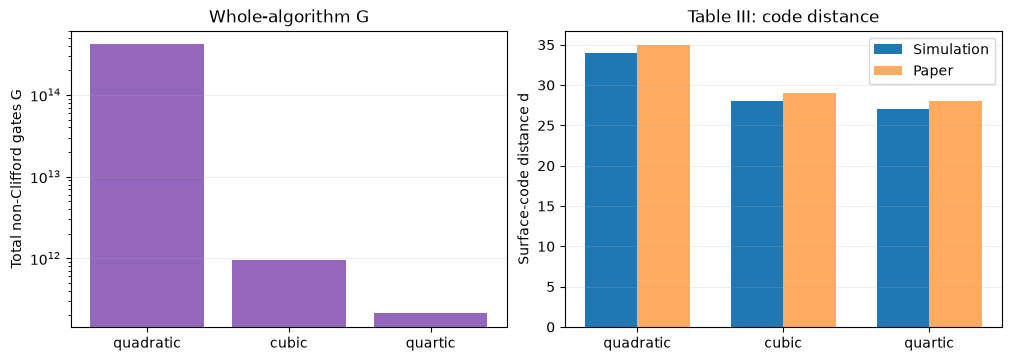

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axs[0].bar(list(xx), [row["G"] for row in rows], color="tab:purple")
axs[0].set_yscale("log")
axs[0].set_ylabel("Total non-Clifford gates G")
axs[0].set_title("Whole-algorithm G")
axs[1].bar([i-.18 for i in xx], [row["d"] for row in rows], .36, label="Simulation")
axs[1].bar([i+.18 for i in xx], [PAPER[name]["d"] for name in names], .36,
           label="Paper", alpha=.65)
axs[1].set_ylabel("Surface-code distance d")
axs[1].set_title("Table III: code distance")
axs[1].legend()
for ax in axs:
    ax.set_xticks(list(xx), names)
    ax.grid(axis="y", alpha=.2)
fig.savefig(RESULTS/"notebook_G_surface.png", dpi=180)
plt.show()